# Práctica 2: Construyendo e interpretando modelos predictivos

**Asignatura:** Inteligencia de Negocios (ICC-321)  
**Integrantes:** Elías De La Cruz Jiménez, Enger Douglas Nuñez Peña  
**Profesora:** Lisibonny Beato  
**Fecha:** 26 de octubre de 2026

Datos: Bank Marketing (UCI) para clasificación, variable objetivo `y`, sin el atributo `duration`. Bike Sharing (UCI) para regresión, variable objetivo `cnt`, sin `casual` ni `registered`.

# 1. Exploración y preparación de los datos

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)

bank = pd.read_csv('data/bank-full.csv', sep=';')
bike = pd.read_csv('data/hour.csv')
print('Bank Marketing:', bank.shape)
print('Bike Sharing:  ', bike.shape)

Bank Marketing: (45211, 17)
Bike Sharing:   (17379, 17)


## 1.1 Estructura de los datos: variables independientes, variable objetivo y qué se quiere predecir

### Bank Marketing (clasificación)

Usamos `bank-full.csv` de Bank Marketing (UCI): 45,211 llamadas de una campaña de telemercadeo de un banco portugués (mayo 2008 a noviembre 2010). Cada fila es un cliente contactado.

**Qué se quiere predecir:** si el cliente contratará un depósito a plazo (`y`: `yes` o `no`). Es una clasificación binaria.

In [2]:
bank.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [3]:
pd.DataFrame({
    'tipo': bank.dtypes.astype(str),
    'valores distintos': bank.nunique(),
    'nulos': bank.isna().sum(),
    "valores 'unknown'": (bank == 'unknown').sum(),
})

,tipo,valores distintos,nulos,valores 'unknown'
age,int64,77,0,0
job,str,12,0,288
marital,str,3,0,0
education,str,4,0,1857
default,str,2,0,0
balance,int64,7168,0,0
housing,str,2,0,0
loan,str,2,0,0
contact,str,3,0,13020
day,int64,31,0,0


No hay nulos, pero varias categóricas usan `'unknown'` como valor faltante. En `poutcome` es el 82% de las filas, porque la mayoría de los clientes nunca fue contactado en una campaña anterior. Lo dejamos como una categoría más: "no sabemos" también es información.

**Variable objetivo:** `y`.

**Variables independientes (15, después de quitar `duration`):**

| Grupo | Variables |
|---|---|
| Datos del cliente | `age`, `job`, `marital`, `education` |
| Situación financiera | `default` (crédito en mora), `balance` (saldo promedio anual en euros), `housing` (préstamo hipotecario), `loan` (préstamo personal) |
| Último contacto de esta campaña | `contact` (celular o fijo), `day`, `month` |
| Historial de campañas | `campaign` (llamadas en esta campaña), `pdays` (días desde el último contacto anterior, -1 si nunca), `previous` (contactos anteriores), `poutcome` (resultado de la campaña anterior) |

Quitamos `duration` (duración de la llamada) porque solo se conoce cuando la llamada termina, y para entonces ya se sabe la respuesta. Usarla haría que el modelo pareciera mucho mejor de lo que sería en la práctica.

In [4]:
bike.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [5]:
print('Nulos en Bike Sharing:', bike.isna().sum().sum())
print('Desde', bike['dteday'].min(), 'hasta', bike['dteday'].max())
print('Comprobación: casual + registered == cnt en todas las filas ->', (bike['casual'] + bike['registered'] == bike['cnt']).all())

Nulos en Bike Sharing: 0
Desde 2011-01-01 hasta 2012-12-31
Comprobación: casual + registered == cnt en todas las filas -> True


### Bike Sharing (regresión)

`hour.csv` tiene 17,379 registros, uno por hora, del 1 de enero de 2011 al 31 de diciembre de 2012. No hay nulos.

**Qué se quiere predecir:** `cnt`, cuántas bicicletas se alquilan en una hora. Es un número, así que es un problema de regresión.

**Variable objetivo:** `cnt`.

**Variables independientes:**

| Grupo | Variables |
|---|---|
| Calendario | `season`, `yr`, `mnth`, `hr`, `holiday`, `weekday`, `workingday` |
| Clima | `weathersit` (1 despejado a 4 tormenta), `temp`, `atemp` (sensación térmica), `hum`, `windspeed` (ya vienen normalizadas entre 0 y 1) |

Se excluyen `casual` y `registered` porque, como comprobamos arriba, su suma es exactamente `cnt`. También `instant` (es el número de fila) y `dteday` (la fecha ya está repartida en `yr`, `mnth`, `weekday` y `hr`).

## 1.2 Análisis exploratorio: estadísticas descriptivas y visualizaciones

### Bank Marketing

In [6]:
num_bank = ['age', 'balance', 'day', 'campaign', 'pdays', 'previous']
cat_bank = ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']

bank = bank.drop(columns=['duration'])
bank[num_bank].describe().round(2)

,age,balance,day,campaign,pdays,previous
count,45211.00,45211.00,45211.00,45211.00,45211.00,45211.00
mean,40.94,1362.27,15.81,2.76,40.20,0.58
std,10.62,3044.77,8.32,3.10,100.13,2.30
min,18.00,-8019.00,1.00,1.00,-1.00,0.00
25%,33.00,72.00,8.00,1.00,-1.00,0.00
50%,39.00,448.00,16.00,2.00,-1.00,0.00
75%,48.00,1428.00,21.00,3.00,-1.00,0.00
max,95.00,102127.00,31.00,63.00,871.00,275.00


In [7]:
print(bank['y'].value_counts())
print()
print(bank['y'].value_counts(normalize=True).round(3))

y
no     39922
yes     5289
Name: count, dtype: int64

y
no     0.883
yes    0.117
Name: proportion, dtype: float64


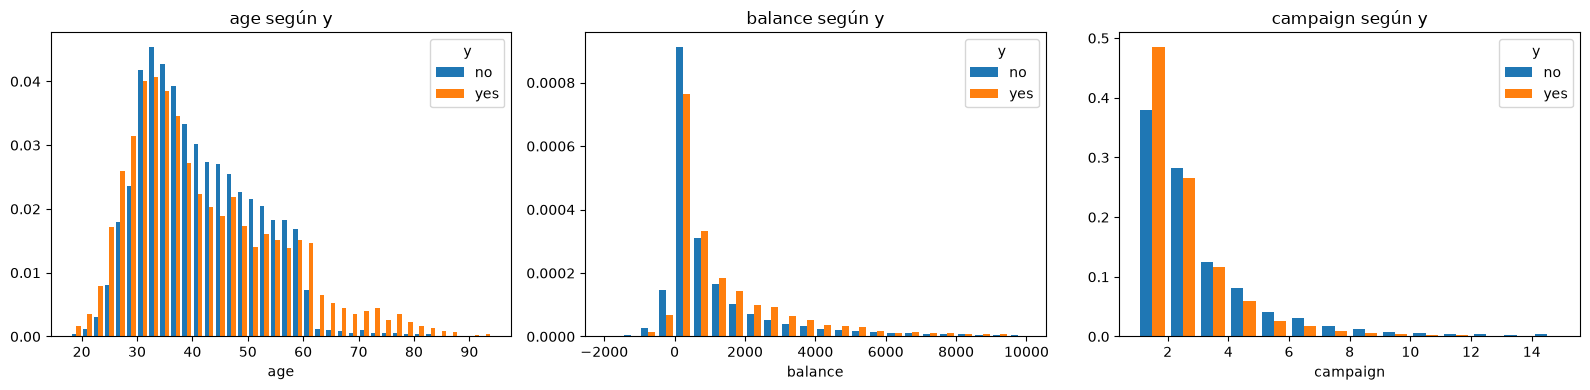

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
# balance y campaign se recortan para que la cola larga no aplaste el gráfico
rangos = {'age': np.arange(18, 96, 2), 'balance': np.arange(-2000, 10001, 500), 'campaign': np.arange(1, 16)}
for ax, (col, bins) in zip(axes, rangos.items()):
    ax.hist([bank.loc[bank['y'] == 'no', col], bank.loc[bank['y'] == 'yes', col]],
            bins=bins, density=True, label=['no', 'yes'])
    ax.set_title(f'{col} según y')
    ax.set_xlabel(col)
    ax.legend(title='y')
plt.tight_layout()
plt.show()

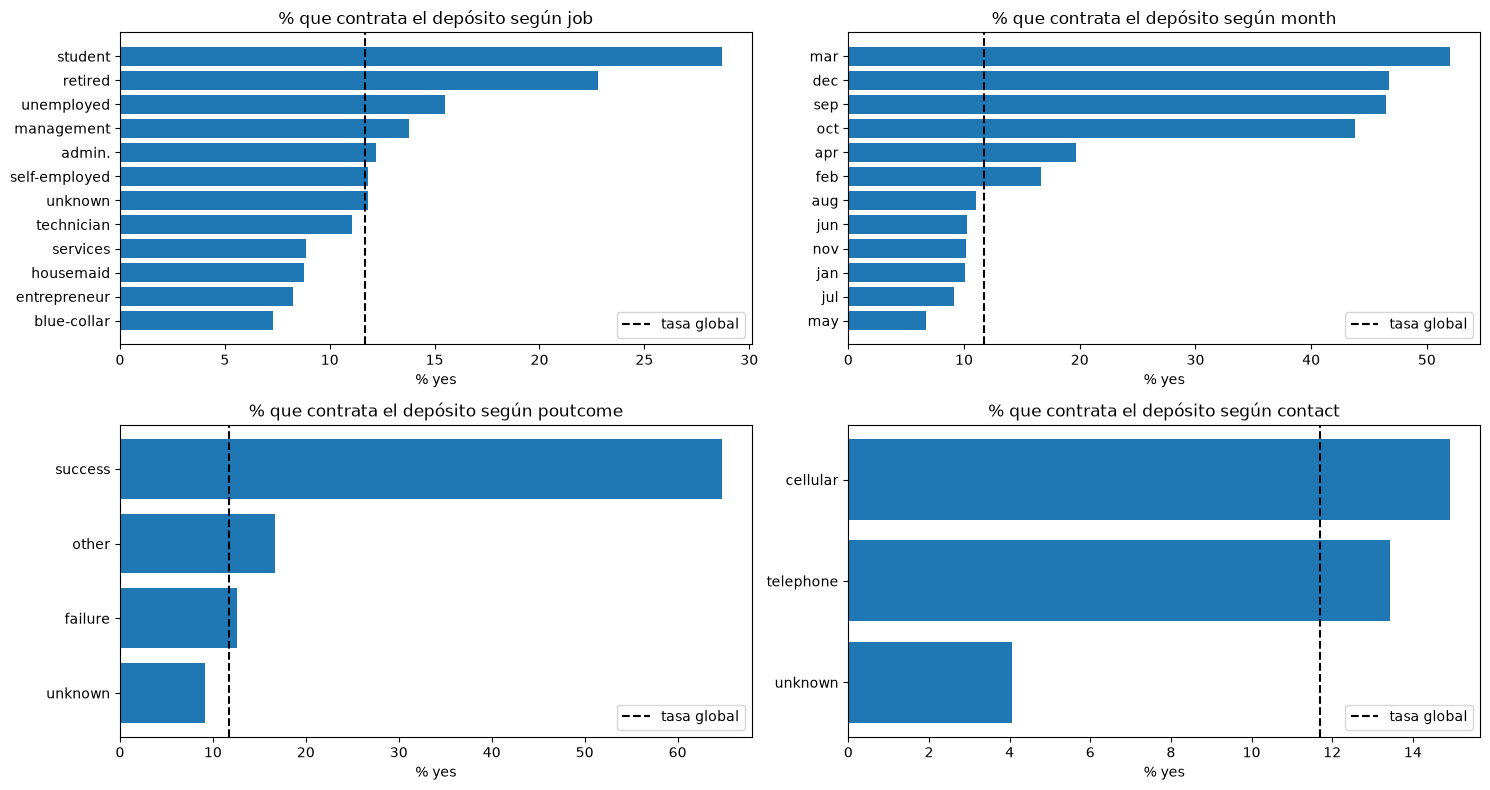

In [9]:
tasa = lambda col: bank.groupby(col)['y'].apply(lambda s: (s == 'yes').mean() * 100).sort_values()

fig, axes = plt.subplots(2, 2, figsize=(15, 8))
for ax, col in zip(axes.ravel(), ['job', 'month', 'poutcome', 'contact']):
    t = tasa(col)
    ax.barh(t.index, t.values)
    ax.axvline((bank['y'] == 'yes').mean() * 100, color='black', linestyle='--', label='tasa global')
    ax.set_title(f'% que contrata el depósito según {col}')
    ax.set_xlabel('% yes')
    ax.legend()
plt.tight_layout()
plt.show()

**Lo que muestran los datos de Bank Marketing:**

- **Clases muy desbalanceadas:** solo el 11.7% de los clientes contrató (5,289 de 45,211). Un modelo que siempre diga "no" tendría 88.3% de accuracy sin servir para nada, así que el accuracy solo no basta para evaluar.
- **`balance` y `campaign` tienen colas muy largas:** la mediana de `balance` es 448 € pero llega a 102,127 €, y hay saldos negativos. Los que contratan tienen más saldo (mediana 733 € contra 417 €).
- **Más llamadas no ayudan:** casi la mitad de los que contratan lo hicieron en la primera llamada. De los clientes llamados más de 5 veces, solo el 5.8% contrató.
- **Edad:** los menores de 30 y los mayores de 60 contratan más que el resto. Coincide con `job`: estudiantes (28.7%) y jubilados (22.8%) son los que más contratan, y los obreros (`blue-collar`, 7.3%) los que menos.
- **`poutcome` es la señal más fuerte:** si el cliente aceptó en la campaña anterior, el 64.7% vuelve a aceptar.
- **Mes:** mayo concentra el 30% de las llamadas pero tiene la peor tasa (6.7%). En marzo, septiembre, octubre y diciembre se llamó poco y la tasa pasa del 40%.
- **`contact`:** cuando no se registró el medio de contacto (`unknown`) la tasa cae al 4.1%.

### Bike Sharing

In [10]:
bike[['temp', 'atemp', 'hum', 'windspeed', 'cnt']].describe().round(3)

,temp,atemp,hum,windspeed,cnt
count,17379.000,17379.000,17379.000,17379.000,17379.000
mean,0.497,0.476,0.627,0.190,189.463
std,0.193,0.172,0.193,0.122,181.388
min,0.020,0.000,0.000,0.000,1.000
25%,0.340,0.333,0.480,0.104,40.000
50%,0.500,0.485,0.630,0.194,142.000
75%,0.660,0.621,0.780,0.254,281.000
max,1.000,1.000,1.000,0.851,977.000


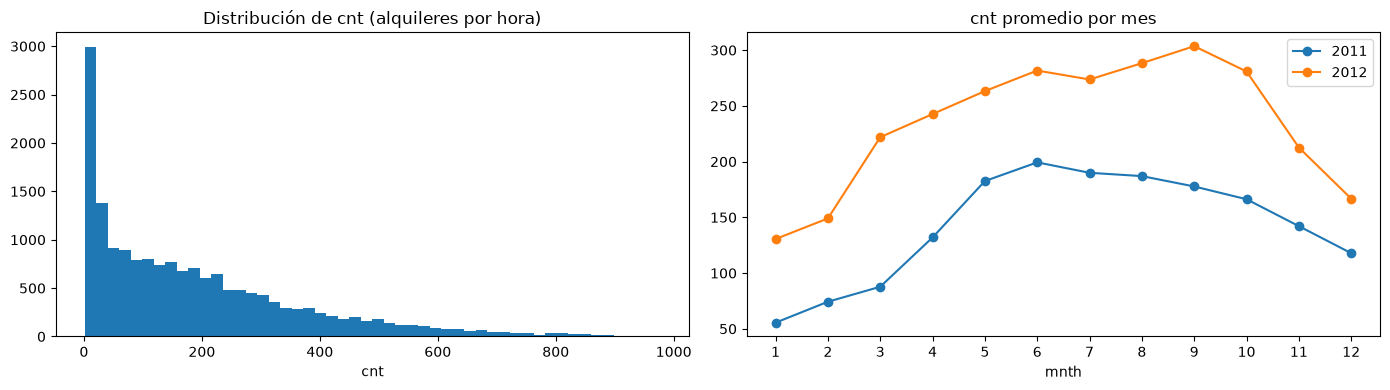

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(bike['cnt'], bins=50)
axes[0].set_title('Distribución de cnt (alquileres por hora)')
axes[0].set_xlabel('cnt')

por_mes = bike.groupby(['yr', 'mnth'])['cnt'].mean().unstack(0)
axes[1].plot(por_mes[0], marker='o', label='2011')
axes[1].plot(por_mes[1], marker='o', label='2012')
axes[1].set_title('cnt promedio por mes')
axes[1].set_xlabel('mnth')
axes[1].set_xticks(range(1, 13))
axes[1].legend()
plt.tight_layout()
plt.show()

**Lo que muestran los datos de Bike Sharing:**

- `cnt` va de 1 a 977, con promedio 189 y mediana 142: la distribución está cargada a la izquierda (muchas horas con poca demanda, sobre todo de madrugada) y una cola de horas pico.
- La demanda tiene estacionalidad: sube en primavera y verano y baja en invierno.
- 2012 tuvo un 63% más de alquileres que 2011 (234.7 contra 143.8 por hora en promedio). Esto importa en la sección 3, porque la partición cronológica deja el final de 2012 para la prueba.
- Las variables climáticas ya vienen normalizadas entre 0 y 1. La relación de cada una con `cnt` y el patrón por hora se analizan en la sección 3.1.

## 1.3 Ingeniería de características: lo investigado, escalado estándar de numéricos y dummies de categóricos

**Lo investigado.** La ingeniería de características es transformar o crear variables para que el modelo aprenda mejor de los datos. Las técnicas más comunes son:

- **Codificación de categóricas (dummies o *one-hot encoding*):** los modelos de scikit-learn solo trabajan con números. Si a `job` le asignáramos 1, 2, 3..., el modelo creería que "3" es mayor que "1", un orden que no existe. Con dummies, cada categoría se convierte en una columna 0/1. Usamos `drop_first=True` para quitar una categoría por variable: se deduce de las demás, y sin ella evitamos columnas redundantes (eso es necesario en la regresión lineal).
- **Escalado estándar:** a cada numérica se le resta su media y se divide entre su desviación estándar, $z = (x - \mu) / \sigma$, para que quede con media 0 y desviación 1. Así `balance` (miles de euros) y `campaign` (unidades) quedan en la misma escala. Ayuda a los modelos que comparan magnitudes, como la regresión lineal, y a Naive Bayes gaussiano. Al árbol de decisión no le cambia nada, porque solo corta por umbrales.
- **Crear variables nuevas** a partir del conocimiento del problema, como un indicador o una combinación de columnas.
- **Quitar variables que filtran la respuesta** (*data leakage*), como `duration`, `casual` y `registered`.

Un punto clave: el escalador se debe ajustar **solo con los datos de entrenamiento**. Si se ajusta con todo, la media y la desviación de la prueba se cuelan en el entrenamiento. Por eso lo metemos en un `Pipeline` que se ajusta después de partir los datos. En la validación cruzada eso hace que se reajuste en cada fold.

**Lo que aplicamos en Bank Marketing:**

1. Quitar `duration`.
2. Crear `contactado_antes` (1 si `pdays` es distinto de -1). En `pdays`, el -1 significa "nunca contactado", no "-1 días". La nueva variable le da ese dato al modelo directamente.
3. Dummies para las 9 categóricas.
4. Escalado estándar para las 6 numéricas.

En Bike Sharing aplicamos la misma regla en la sección 3.2: dummies para `season`, `mnth`, `hr`, `weekday` y `weathersit`, y escalado para `temp`, `atemp`, `hum` y `windspeed`.

In [12]:
bank['contactado_antes'] = (bank['pdays'] != -1).astype(int)

X_bank = pd.get_dummies(bank.drop(columns=['y']), columns=cat_bank, drop_first=True, dtype=int)
y_bank = (bank['y'] == 'yes').astype(int)

print('Columnas originales sin y ni duration:', bank.shape[1] - 2)
print('Columnas después de las dummies:     ', X_bank.shape[1])
X_bank.head()

Columnas originales sin y ni duration: 15
Columnas después de las dummies:      42


,age,balance,day,campaign,pdays,previous,contactado_antes,job_blue-collar,job_entrepreneur,job_housemaid,...,month_jul,month_jun,month_mar,month_may,month_nov,month_oct,month_sep,poutcome_other,poutcome_success,poutcome_unknown
0,58,2143,5,1,-1,0,0,0,0,0,...,0,0,0,1,0,0,0,0,0,1
1,44,29,5,1,-1,0,0,0,0,0,...,0,0,0,1,0,0,0,0,0,1
2,33,2,5,1,-1,0,0,0,1,0,...,0,0,0,1,0,0,0,0,0,1
3,47,1506,5,1,-1,0,0,1,0,0,...,0,0,0,1,0,0,0,0,0,1
4,33,1,5,1,-1,0,0,0,0,0,...,0,0,0,1,0,0,0,0,0,1


In [13]:
# Escalado estándar de las numéricas. Las dummies pasan sin cambios.
# Va dentro de un Pipeline para que se ajuste solo con los datos de entrenamiento.
preprocesador = ColumnTransformer([('num', StandardScaler(), num_bank)], remainder='passthrough')

demo = preprocesador.fit_transform(X_bank)
pd.DataFrame(demo[:, :len(num_bank)], columns=num_bank).describe().loc[['mean', 'std']].round(3)

,age,balance,day,campaign,pdays,previous
mean,0.0,0.0,0.0,0.0,0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0


**Resultados de esta etapa:**

- Bank Marketing pasó de 15 columnas a 42: las 6 numéricas, `contactado_antes` y 35 dummies. Bike Sharing queda con 53 columnas (sección 3.2).
- La tabla de arriba es solo una demostración, con el escalador ajustado a todos los datos: las numéricas quedan con media 0 y desviación 1. En los modelos, el mismo `preprocesador` se ajusta solo con el entrenamiento.
- No imputamos los `'unknown'`. Al convertirse en su propia dummy, el modelo puede aprender si "no sabemos" se relaciona con la respuesta (y en `contact` claramente sí).

# 2. Modelos de clasificación (Bank Marketing)

## 2.1 Naive Bayes y árbol de decisión con partición 80/20 estratificada

In [14]:
X_train_clf, X_test_clf, y_train_clf, y_test_clf = train_test_split(
    X_bank, y_bank, test_size=0.2, stratify=y_bank, random_state=42)

pd.DataFrame({
    'filas': [len(y_bank), len(y_train_clf), len(y_test_clf)],
    '% yes': [y_bank.mean() * 100, y_train_clf.mean() * 100, y_test_clf.mean() * 100],
}, index=['Total', 'Entrenamiento', 'Prueba']).round(2)

,filas,% yes
Total,45211,11.7
Entrenamiento,36168,11.7
Prueba,9043,11.7


`stratify=y_bank` mantiene la misma proporción de `yes` (11.7%) en entrenamiento y prueba. Sin eso, por azar, la prueba podría tener más o menos clientes positivos y las métricas no serían comparables.

**Naive Bayes:** usamos `GaussianNB`. Calcula la probabilidad de cada clase suponiendo que las variables son independientes entre sí dado la clase, y que cada una sigue una distribución normal. No tiene hiperparámetros que ajustar.

**Árbol de decisión:** hay que escoger dos cosas.

- `class_weight='balanced'`: con solo 11.7% de positivos, un árbol normal aprende a decir casi siempre "no". Esta opción le da más peso a cada `yes` durante el entrenamiento, en proporción inversa a su frecuencia.
- `max_depth`: sin límite el árbol memoriza el entrenamiento. Probamos varias profundidades con validación cruzada estratificada sobre el entrenamiento (sin tocar la prueba) y comparamos el F1 de la clase `yes`.

In [15]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for profundidad in [3, 5, 7, 10, 15, None]:
    modelo = Pipeline([('pre', preprocesador),
                       ('arbol', DecisionTreeClassifier(max_depth=profundidad, class_weight='balanced', random_state=42))])
    cv = cross_validate(modelo, X_train_clf, y_train_clf, cv=skf, scoring=['f1', 'recall', 'precision'])
    print(f"max_depth={profundidad}: F1 = {cv['test_f1'].mean():.3f}, "
          f"recall = {cv['test_recall'].mean():.3f}, precisión = {cv['test_precision'].mean():.3f}")

max_depth=3: F1 = 0.311, recall = 0.651, precisión = 0.205


max_depth=5: F1 = 0.380, recall = 0.541, precisión = 0.293


max_depth=7: F1 = 0.425, recall = 0.546, precisión = 0.349


max_depth=10: F1 = 0.407, recall = 0.565, precisión = 0.320


max_depth=15: F1 = 0.366, recall = 0.516, precisión = 0.285


max_depth=None: F1 = 0.301, recall = 0.304, precisión = 0.298


`max_depth=7` da el mejor F1 (0.425). Con menos profundidad el árbol es demasiado simple y marca a casi todos como `yes` (precisión de 0.205 con profundidad 3). Sin límite, el F1 cae a 0.301 por sobreajuste. Entrenamos el árbol final con `max_depth=7`.

In [16]:
naive_bayes = Pipeline([('pre', preprocesador), ('nb', GaussianNB())])
arbol_clf = Pipeline([('pre', preprocesador),
                      ('arbol', DecisionTreeClassifier(max_depth=7, class_weight='balanced', random_state=42))])

naive_bayes.fit(X_train_clf, y_train_clf)
arbol_clf.fit(X_train_clf, y_train_clf)

pred_nb = naive_bayes.predict(X_test_clf)
pred_arbol_clf = arbol_clf.predict(X_test_clf)

## 2.2 Accuracy, precisión, recall y F1

La clase positiva es `yes` (contrata el depósito):

- **Accuracy:** de todos los clientes, qué porcentaje clasificó bien.
- **Precisión:** de los que el modelo marcó como `yes`, cuántos contrataron de verdad.
- **Recall:** de los que contrataron de verdad, cuántos encontró el modelo.
- **F1-score:** la media armónica de precisión y recall. Solo es alto si las dos lo son.

In [17]:
modelos_clf = {'Naive Bayes': pred_nb, 'Árbol de decisión': pred_arbol_clf}

metricas_clf = pd.DataFrame({
    nombre: {
        'Accuracy': accuracy_score(y_test_clf, pred),
        'Precisión': precision_score(y_test_clf, pred),
        'Recall': recall_score(y_test_clf, pred),
        'F1-score': f1_score(y_test_clf, pred),
    } for nombre, pred in modelos_clf.items()
}).T
metricas_clf.round(3)

,Accuracy,Precisión,Recall,F1-score
Naive Bayes,0.847,0.368,0.436,0.399
Árbol de decisión,0.832,0.359,0.558,0.437


In [18]:
for nombre, pred in modelos_clf.items():
    print(nombre)
    print(classification_report(y_test_clf, pred, target_names=['no', 'yes'], digits=3))

Naive Bayes
              precision    recall  f1-score   support

          no      0.923     0.901     0.912      7985
         yes      0.368     0.436     0.399      1058

    accuracy                          0.847      9043
   macro avg      0.646     0.668     0.656      9043
weighted avg      0.858     0.847     0.852      9043

Árbol de decisión
              precision    recall  f1-score   support

          no      0.937     0.868     0.901      7985
         yes      0.359     0.558     0.437      1058

    accuracy                          0.832      9043
   macro avg      0.648     0.713     0.669      9043
weighted avg      0.869     0.832     0.847      9043



- **Accuracy:** Naive Bayes tiene más (84.7% contra 83.2%), pero los dos quedan por debajo del 88.3% de decir siempre "no". Con este desbalance el accuracy engaña, y por eso nos fijamos en las métricas de la clase `yes`.
- **Precisión:** casi igual en los dos (0.368 y 0.359). Más o menos 1 de cada 3 clientes que el modelo recomienda llamar termina contratando, el triple de la tasa base del 11.7%.
- **Recall:** aquí está la diferencia. El árbol encuentra el 55.8% de los clientes que contratan, Naive Bayes solo el 43.6%.
- **F1:** gana el árbol (0.437 contra 0.399), porque mejora mucho el recall sin perder casi nada de precisión.
- La clase `no` se predice bien en los dos (F1 de 0.90 a 0.91). Lo difícil es reconocer a los `yes`.

## 2.3 Matrices de confusión: interpretación y métricas calculadas a mano contra scikit-learn

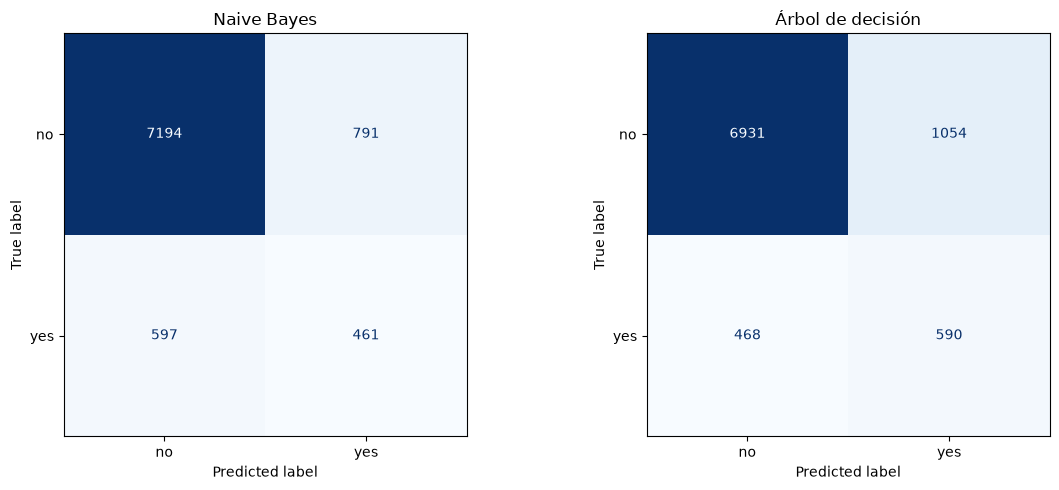

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (nombre, pred) in zip(axes, modelos_clf.items()):
    ConfusionMatrixDisplay.from_predictions(y_test_clf, pred, display_labels=['no', 'yes'],
                                            values_format='d', cmap='Blues', colorbar=False, ax=ax)
    ax.set_title(nombre)
plt.tight_layout()
plt.show()

En las matrices, las filas son la clase real y las columnas la predicha:

| | Naive Bayes | Árbol de decisión |
|---|---|---|
| **TN** (no y dijo no) | 7,194 | 6,931 |
| **FP** (no, pero dijo yes) | 791 | 1,054 |
| **FN** (yes, pero dijo no) | 597 | 468 |
| **TP** (yes y dijo yes) | 461 | 590 |

- De los 1,058 clientes de prueba que contrataron, el árbol encuentra 590 y Naive Bayes 461: **129 clientes más**.
- A cambio, el árbol hace 263 llamadas más a clientes que no contratarán (1,054 FP contra 791).
- Naive Bayes deja escapar a más de la mitad de los interesados (597 FN de 1,058).
- Los dos modelos marcan como `yes` a muchos clientes que no lo son. Esto es normal: los `no` son 7.5 veces más que los `yes`, y aunque el modelo se equivoque solo con una parte pequeña de ellos, eso suma muchas llamadas.

**Cálculo manual de las métricas.** Sacamos TP, TN, FP y FN de cada matriz y aplicamos las fórmulas:

$$\text{Accuracy} = \frac{TP + TN}{TP + TN + FP + FN} \qquad \text{Precisión} = \frac{TP}{TP + FP}$$

$$\text{Recall} = \frac{TP}{TP + FN} \qquad F1 = \frac{2 \cdot \text{Precisión} \cdot \text{Recall}}{\text{Precisión} + \text{Recall}}$$

In [20]:
filas = []
for nombre, pred in modelos_clf.items():
    tn, fp, fn, tp = confusion_matrix(y_test_clf, pred).ravel()
    print(f'{nombre}: TP={tp}, TN={tn}, FP={fp}, FN={fn}')

    accuracy = (tp + tn) / (tp + tn + fp + fn)
    precision = tp / (tp + fp)
    recall = tp / (tp + fn)
    f1 = 2 * precision * recall / (precision + recall)

    print(f'  Accuracy  = ({tp} + {tn}) / {tp + tn + fp + fn} = {accuracy:.4f}')
    print(f'  Precisión = {tp} / ({tp} + {fp}) = {precision:.4f}')
    print(f'  Recall    = {tp} / ({tp} + {fn}) = {recall:.4f}')
    print(f'  F1        = 2 * {precision:.4f} * {recall:.4f} / ({precision:.4f} + {recall:.4f}) = {f1:.4f}')
    print()

    sk = [accuracy_score(y_test_clf, pred), precision_score(y_test_clf, pred),
          recall_score(y_test_clf, pred), f1_score(y_test_clf, pred)]
    for metrica, manual, valor_sk in zip(['Accuracy', 'Precisión', 'Recall', 'F1-score'], [accuracy, precision, recall, f1], sk):
        filas.append([nombre, metrica, manual, valor_sk, np.isclose(manual, valor_sk)])

pd.DataFrame(filas, columns=['Modelo', 'Métrica', 'Manual', 'scikit-learn', '¿Coinciden?']).round(4)

Naive Bayes: TP=461, TN=7194, FP=791, FN=597
  Accuracy  = (461 + 7194) / 9043 = 0.8465
  Precisión = 461 / (461 + 791) = 0.3682
  Recall    = 461 / (461 + 597) = 0.4357
  F1        = 2 * 0.3682 * 0.4357 / (0.3682 + 0.4357) = 0.3991

Árbol de decisión: TP=590, TN=6931, FP=1054, FN=468
  Accuracy  = (590 + 6931) / 9043 = 0.8317
  Precisión = 590 / (590 + 1054) = 0.3589
  Recall    = 590 / (590 + 468) = 0.5577
  F1        = 2 * 0.3589 * 0.5577 / (0.3589 + 0.5577) = 0.4367



,Modelo,Métrica,Manual,scikit-learn,¿Coinciden?
0,Naive Bayes,Accuracy,0.8465,0.8465,True
1,Naive Bayes,Precisión,0.3682,0.3682,True
2,Naive Bayes,Recall,0.4357,0.4357,True
3,Naive Bayes,F1-score,0.3991,0.3991,True
4,Árbol de decisión,Accuracy,0.8317,0.8317,True
5,Árbol de decisión,Precisión,0.3589,0.3589,True
6,Árbol de decisión,Recall,0.5577,0.5577,True
7,Árbol de decisión,F1-score,0.4367,0.4367,True


Los valores calculados a mano coinciden con los de scikit-learn en las cuatro métricas de los dos modelos. Por ejemplo, la precisión del árbol: de 1,644 clientes que marcó como `yes` (590 + 1,054), acertó 590, o sea 35.9%. Las funciones de scikit-learn hacen exactamente estas cuentas sobre la matriz de confusión, tomando `yes` (1) como clase positiva.

## 2.4 Validación cruzada estratificada de 5 folds sobre el entrenamiento

In [21]:
filas = {}
for nombre, modelo in {'Naive Bayes': naive_bayes, 'Árbol de decisión': arbol_clf}.items():
    cv = cross_validate(modelo, X_train_clf, y_train_clf, cv=skf,
                        scoring=['accuracy', 'precision', 'recall', 'f1'])
    for metrica in ['accuracy', 'precision', 'recall', 'f1']:
        valores = cv[f'test_{metrica}']
        filas[(nombre, metrica)] = {**{f'fold {i + 1}': v for i, v in enumerate(valores)},
                                    'media': valores.mean(), 'desv. estándar': valores.std()}

pd.DataFrame(filas).T.round(3)

fold 1  fold 2  fold 3  fold 4  fold 5  media  \
Naive Bayes       accuracy    0.842   0.840   0.848   0.846   0.837  0.843   
                  precision   0.353   0.357   0.370   0.362   0.338  0.356   
                  recall      0.424   0.455   0.421   0.414   0.408  0.424   
                  f1          0.385   0.400   0.394   0.386   0.370  0.387   
Árbol de decisión accuracy    0.836   0.832   0.834   0.789   0.839  0.826   
                  precision   0.364   0.357   0.357   0.295   0.372  0.349   
                  recall      0.538   0.545   0.524   0.578   0.544  0.546   
                  f1          0.434   0.431   0.425   0.391   0.441  0.425   

                             desv. estándar  
Naive Bayes       accuracy            0.004  
                  precision           0.011  
                  recall              0.016  
                  f1                  0.010  
Árbol de decisión accuracy            0.018  
                  precision           0.027  
                  recall              0.018  
                  f1                  0.018

- Los promedios de la validación cruzada se parecen mucho a los de la prueba (F1 de 0.387 contra 0.399 en Naive Bayes; 0.425 contra 0.437 en el árbol). Los resultados de la prueba no fueron suerte de la partición.
- El árbol sigue ganando en recall y F1 en el promedio de los 5 folds. También en cada fold, salvo el 4, donde baja a 0.391 y queda casi empatado con Naive Bayes.
- Naive Bayes es más estable: su desviación estándar es de 0.004 a 0.016, la del árbol de 0.018 a 0.027. Es lo esperado: un árbol cambia más cuando cambian un poco los datos con los que se entrena. El fold 4 muestra esa variabilidad.
- Ninguno muestra señales de sobreajuste grave: lo que rinden en validación se mantiene en la prueba.

## 2.5 Comparación y modelo elegido

| | Naive Bayes | Árbol de decisión |
|---|---|---|
| Accuracy (prueba) | **0.847** | 0.832 |
| Precisión (prueba) | **0.368** | 0.359 |
| Recall (prueba) | 0.436 | **0.558** |
| F1 (prueba) | 0.399 | **0.437** |
| F1 (validación cruzada) | 0.387 ± 0.010 | **0.425 ± 0.018** |
| Clientes que contratan encontrados | 461 de 1,058 | **590 de 1,058** |

**Modelo elegido: el árbol de decisión.**

- Encuentra 129 clientes interesados más que Naive Bayes, con una precisión casi igual (0.359 contra 0.368).
- Tiene mejor F1 en la prueba y en la validación cruzada, así que la ventaja se repite.
- Se puede interpretar: sus reglas se pueden leer como "si el cliente aceptó en la campaña anterior y se le llama en tal mes, entonces...", lo que ayuda a explicarle la decisión al área comercial.
- Naive Bayes supone que las variables son independientes y que las numéricas son normales. Aquí no se cumple: `contactado_antes`, `pdays`, `previous` y `poutcome` dicen casi lo mismo, y `balance` y `campaign` están muy sesgadas.

Lo que se pierde es un poco de accuracy (que con este desbalance no es la métrica que importa) y algo de estabilidad entre folds.

## 2.6 Pregunta de análisis: consecuencias de falsos positivos y falsos negativos, y la métrica más importante

**Falso positivo:** el modelo dice que el cliente contratará, pero no lo hace. El banco hace una llamada que no da resultado: gasta tiempo del agente y molesta al cliente. Si pasa mucho, el cliente puede sentirse acosado y quejarse o dejar de contestar.

**Falso negativo:** el modelo dice que no contratará, pero sí lo habría hecho. El banco no lo llama y pierde un depósito, es decir, dinero que habría captado. Ese cliente puede terminar en otro banco.

**Qué es más grave.** En general, el falso negativo. Una llamada cuesta unos minutos de un agente, y un depósito a plazo representa dinero que el banco puede prestar durante meses o años. Con el árbol, cada FN es un cliente que se pierde sin que nadie se entere.

**Métrica más importante: el recall de la clase `yes`**, sin descuidar la precisión. El accuracy no sirve aquí: un modelo que nunca llama a nadie tiene 88.3% de accuracy y le hace perder al banco el 100% de los clientes. El recall mide justo lo que importa: qué parte de los clientes interesados logramos encontrar.

Pero si se mira solo el recall, se llega al extremo de llamar a todos. Por eso hay que mirarlo junto con la precisión, o usar el **F1**, que fue el criterio que usamos para ajustar el árbol. Si el banco conoce cuánto cuesta una llamada y cuánto gana por depósito, puede ajustar el umbral de decisión del modelo para encontrar el mejor balance. Si las llamadas son caras o el equipo es pequeño, la precisión pasa a ser más importante.

# 3. Modelos de regresión (Bike Sharing)

Usamos `hour.csv` de Bike Sharing (UCI): alquileres por hora de Capital Bikeshare (Washington D.C.) en 2011 y 2012. Queremos predecir `cnt`, el total de bicicletas alquiladas en una hora. Quitamos `casual` y `registered` porque su suma es `cnt`, e `instant` porque es solo el número de fila.

In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

bike = pd.read_csv('data/hour.csv')
bike = bike.drop(columns=['instant', 'casual', 'registered'])
bike.head()

,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,cnt
0,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,16
1,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,40
2,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,32
3,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,13
4,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,1


In [23]:
numericas = ['temp', 'atemp', 'hum', 'windspeed']
categoricas = ['season', 'mnth', 'hr', 'weekday', 'weathersit']

bike[numericas + ['cnt']].describe()

,temp,atemp,hum,windspeed,cnt
count,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,0.496987,0.475775,0.627229,0.190098,189.463088
std,0.192556,0.171850,0.192930,0.122340,181.387599
min,0.020000,0.000000,0.000000,0.000000,1.000000
25%,0.340000,0.333300,0.480000,0.104500,40.000000
50%,0.500000,0.484800,0.630000,0.194000,142.000000
75%,0.660000,0.621200,0.780000,0.253700,281.000000
max,1.000000,1.000000,1.000000,0.850700,977.000000


## 3.1 Relaciones con `cnt`: diagramas de dispersión y correlaciones

In [24]:
bike.drop(columns=['dteday']).corr()['cnt'].sort_values(ascending=False)

cnt           1.000000
temp          0.404772
atemp         0.400929
hr            0.394071
yr            0.250495
season        0.178056
mnth          0.120638
windspeed     0.093234
workingday    0.030284
weekday       0.026900
holiday      -0.030927
weathersit   -0.142426
hum          -0.322911
Name: cnt, dtype: float64

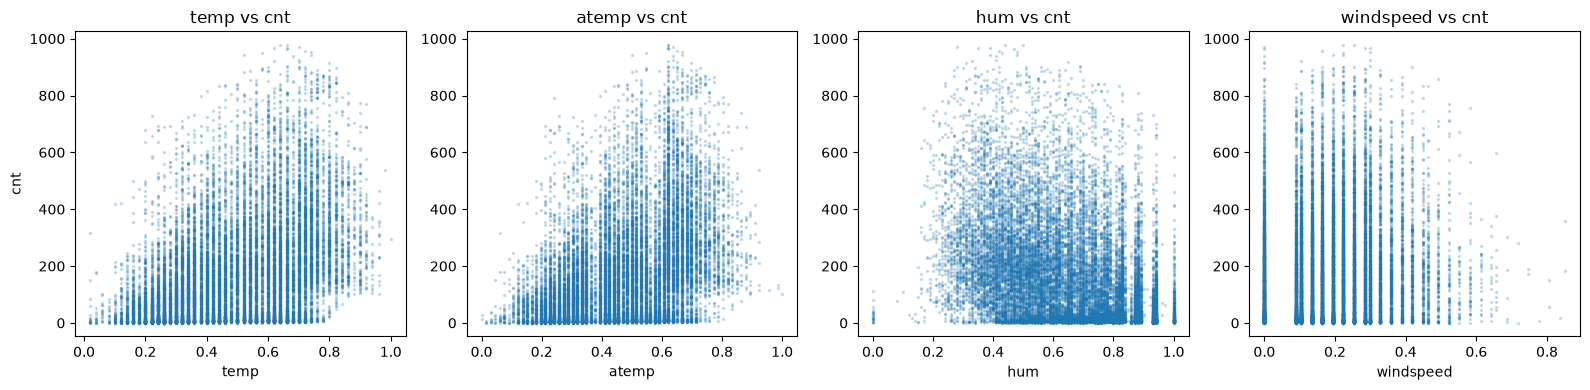

In [25]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, numericas):
    ax.scatter(bike[col], bike['cnt'], s=2, alpha=0.2)
    ax.set_title(f'{col} vs cnt')
    ax.set_xlabel(col)
axes[0].set_ylabel('cnt')
plt.tight_layout()
plt.show()

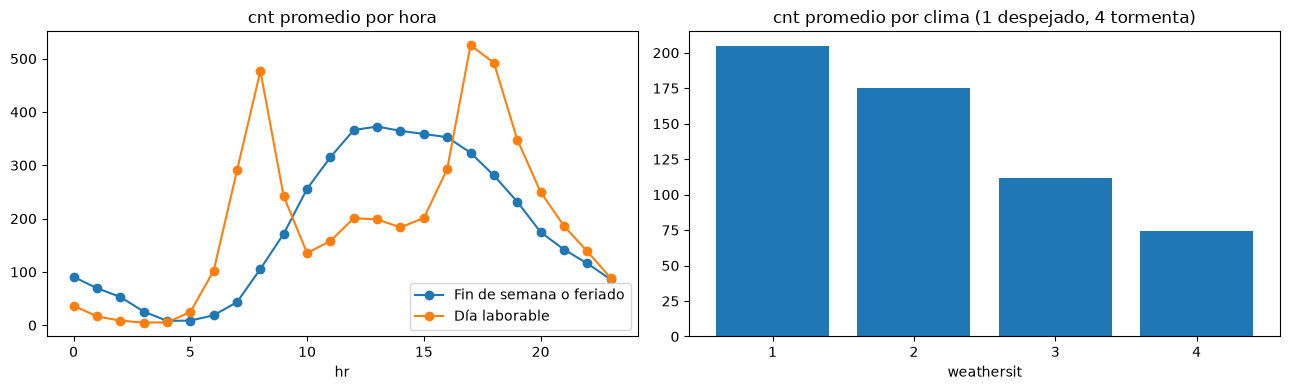

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

por_hora = bike.groupby(['hr', 'workingday'])['cnt'].mean().unstack()
axes[0].plot(por_hora[0], marker='o', label='Fin de semana o feriado')
axes[0].plot(por_hora[1], marker='o', label='Día laborable')
axes[0].set_title('cnt promedio por hora')
axes[0].set_xlabel('hr')
axes[0].legend()

por_clima = bike.groupby('weathersit')['cnt'].mean()
axes[1].bar(por_clima.index, por_clima.values)
axes[1].set_title('cnt promedio por clima (1 despejado, 4 tormenta)')
axes[1].set_xlabel('weathersit')
axes[1].set_xticks(por_clima.index)
plt.tight_layout()
plt.show()

- La temperatura es la numérica que más se relaciona con la demanda (r = 0.40): más calor, más alquileres. `temp` y `atemp` están casi duplicadas entre sí (r = 0.99).
- La humedad va en contra (r = -0.32) y el viento casi no influye (r = 0.09).
- La hora es lo que más pesa, pero no en línea recta: los días laborables tienen dos picos (8:00 y 17:00 a 18:00, ir y volver del trabajo) y los fines de semana una sola loma al mediodía. Por eso `hr` se trata como categórica y no como número.
- Con mal clima baja la demanda: de 205 alquileres por hora con cielo despejado a 112 con lluvia.
- `yr` tiene r = 0.25: en 2012 se alquiló más que en 2011.

## 3.2 Preparación y partición 80/20 en orden cronológico

Aplicamos la regla de la sección 1.3: dummies para las categóricas y escalado estándar para las numéricas. El escalador se ajusta solo con el entrenamiento, para que la prueba no influya en él.

Para la partición usamos `shuffle=False`: el 80% más antiguo entrena y el 20% más reciente prueba. Si mezcláramos las filas, el modelo entrenaría con horas del futuro que luego se le pide predecir. El archivo ya viene ordenado por fecha y hora.

In [27]:
X = bike.drop(columns=['dteday', 'cnt'])
X = pd.get_dummies(X, columns=categoricas, drop_first=True)
y = bike['cnt']

X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(X, y, test_size=0.2, shuffle=False)

scaler = StandardScaler()
X_train_reg[numericas] = scaler.fit_transform(X_train_reg[numericas])
X_test_reg[numericas] = scaler.transform(X_test_reg[numericas])

print('Columnas después de las dummies:', X.shape[1])
print('Entrenamiento:', bike['dteday'].iloc[0], 'a', bike['dteday'].iloc[len(X_train_reg) - 1])
print('Prueba:       ', bike['dteday'].iloc[len(X_train_reg)], 'a', bike['dteday'].iloc[-1])
print('cnt promedio en entrenamiento:', round(y_train_reg.mean(), 1))
print('cnt promedio en prueba:       ', round(y_test_reg.mean(), 1))

Columnas después de las dummies: 53
Entrenamiento: 2011-01-01 a 2012-08-07
Prueba:        2012-08-07 a 2012-12-31
cnt promedio en entrenamiento: 174.6
cnt promedio en prueba:        248.8


La prueba cubre agosto a diciembre de 2012, cuando el sistema ya había crecido: su demanda promedio es 42% mayor que la del entrenamiento. Eso hace la prueba más difícil, y es lo que pasaría en la vida real.

## 3.3 Regresión lineal múltiple y árbol de decisión para regresión

In [28]:
lineal = LinearRegression()
lineal.fit(X_train_reg, y_train_reg)

coeficientes = pd.Series(lineal.coef_, index=X.columns)
coeficientes.sort_values(ascending=False).head(5)

hr_17    348.291751
hr_18    322.067397
hr_8     283.618858
hr_19    223.163753
hr_16    203.775535
dtype: float64

Los coeficientes más grandes son las horas pico: a las 17:00 se alquilan unas 348 bicicletas más que a medianoche, con todo lo demás igual.

Para el árbol hay que escoger `max_depth`, porque sin límite memoriza el entrenamiento. Probamos varias profundidades con una validación: el último 20% del entrenamiento, también sin mezclar. Así no usamos la prueba para escoger.

In [29]:
X_sub, X_val, y_sub, y_val = train_test_split(X_train_reg, y_train_reg, test_size=0.2, shuffle=False)

for profundidad in [5, 10, 15, 20, None]:
    arbol = DecisionTreeRegressor(max_depth=profundidad, random_state=42)
    arbol.fit(X_sub, y_sub)
    rmse = mean_squared_error(y_val, arbol.predict(X_val)) ** 0.5
    print(f'max_depth={profundidad}: RMSE en validación = {rmse:.1f}')

max_depth=5: RMSE en validación = 170.7
max_depth=10: RMSE en validación = 155.8
max_depth=15: RMSE en validación = 130.0
max_depth=20: RMSE en validación = 137.9


max_depth=None: RMSE en validación = 130.5


In [30]:
arbol = DecisionTreeRegressor(max_depth=15, random_state=42)
arbol.fit(X_train_reg, y_train_reg)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",15
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with `

`max_depth=15` dio el menor error en validación, así que entrenamos el árbol final con esa profundidad y todo el entrenamiento.

## 3.4 MAE, RMSE y R²

- **MAE**: cuántas bicicletas se equivoca el modelo en promedio.
- **RMSE**: parecido, pero castiga más los errores grandes.
- **R²**: qué parte de la variación de `cnt` explica el modelo (1 es perfecto, 0 es igual que predecir siempre el promedio).

In [31]:
pred_lineal = lineal.predict(X_test_reg)
pred_arbol = arbol.predict(X_test_reg)

resultados = pd.DataFrame({
    'MAE': [mean_absolute_error(y_test_reg, pred_lineal), mean_absolute_error(y_test_reg, pred_arbol)],
    'RMSE': [mean_squared_error(y_test_reg, pred_lineal) ** 0.5, mean_squared_error(y_test_reg, pred_arbol) ** 0.5],
    'R² prueba': [r2_score(y_test_reg, pred_lineal), r2_score(y_test_reg, pred_arbol)],
    'R² entrenamiento': [lineal.score(X_train_reg, y_train_reg), arbol.score(X_train_reg, y_train_reg)],
}, index=['Regresión lineal', 'Árbol de decisión'])
resultados.round(3)

,MAE,RMSE,R² prueba,R² entrenamiento
Regresión lineal,98.798,133.835,0.632,0.689
Árbol de decisión,81.601,119.682,0.705,0.883


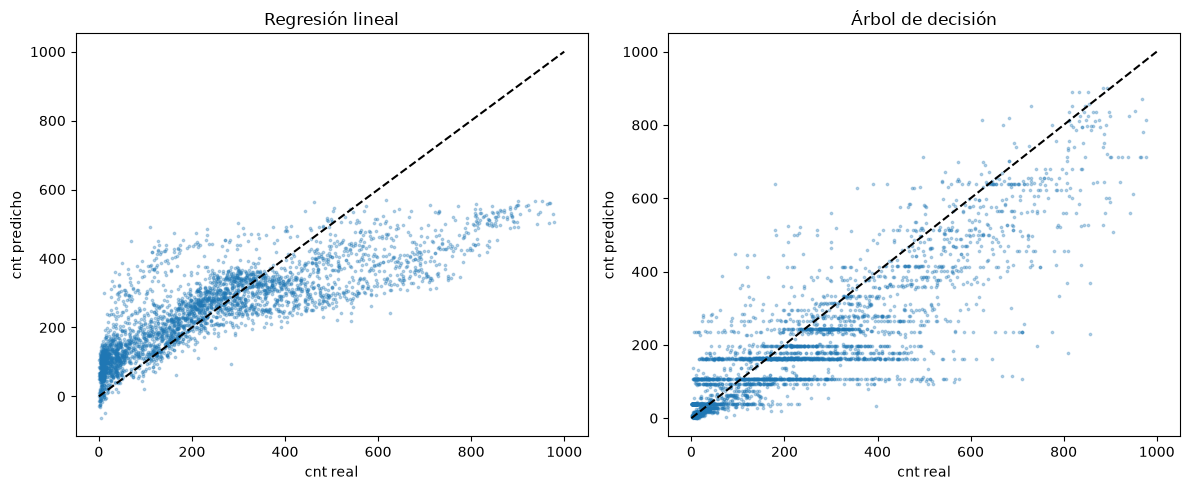

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, pred, nombre in zip(axes, [pred_lineal, pred_arbol], ['Regresión lineal', 'Árbol de decisión']):
    ax.scatter(y_test_reg, pred, s=3, alpha=0.3)
    ax.plot([0, 1000], [0, 1000], color='black', linestyle='--')
    ax.set_title(nombre)
    ax.set_xlabel('cnt real')
    ax.set_ylabel('cnt predicho')
plt.tight_layout()
plt.show()

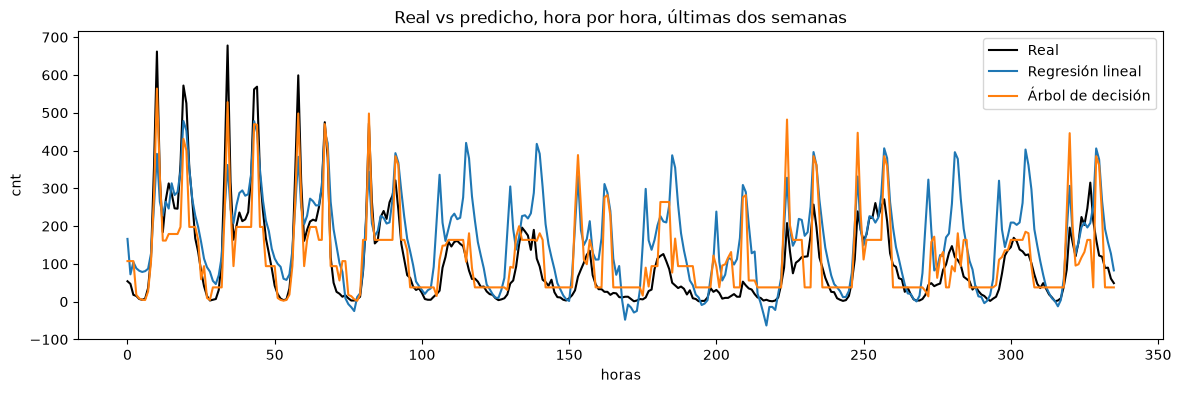

In [33]:
# Últimas dos semanas de la prueba (18 al 31 de diciembre de 2012)
plt.figure(figsize=(14, 4))
plt.plot(y_test_reg.values[-336:], color='black', label='Real')
plt.plot(pred_lineal[-336:], label='Regresión lineal')
plt.plot(pred_arbol[-336:], label='Árbol de decisión')
plt.title('Real vs predicho, hora por hora, últimas dos semanas')
plt.xlabel('horas')
plt.ylabel('cnt')
plt.legend()
plt.show()

El árbol gana en las tres métricas. En la dispersión, sus puntos están más cerca de la línea punteada (la predicción perfecta). En las dos últimas semanas, los dos modelos copian bien la forma del día, pero en Navidad predicen mucho más de lo que realmente se alquiló.

## 3.5 Análisis de errores y modelo elegido

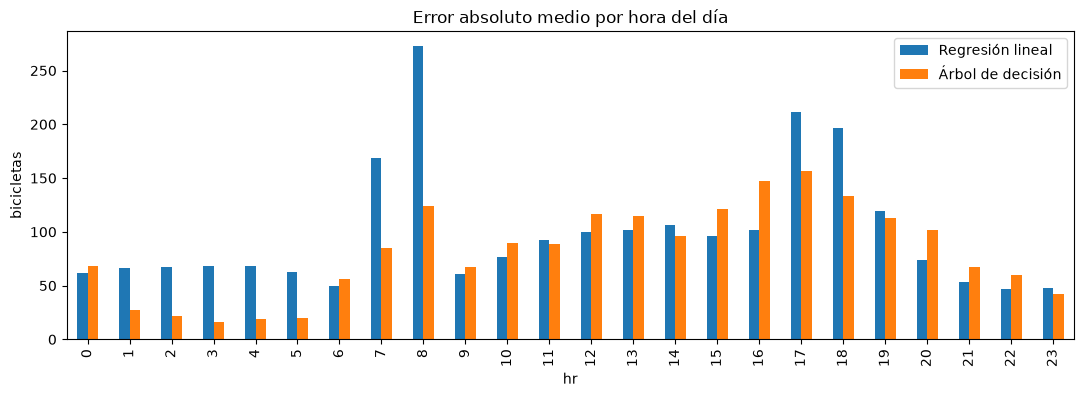

Predicciones negativas de la regresión lineal: 22
Error medio del árbol (predicho - real): -46.4


In [34]:
errores = pd.DataFrame({
    'hr': bike['hr'].iloc[len(X_train_reg):].values,
    'Regresión lineal': np.abs(pred_lineal - y_test_reg.values),
    'Árbol de decisión': np.abs(pred_arbol - y_test_reg.values),
})
errores.groupby('hr').mean().plot.bar(figsize=(13, 4), title='Error absoluto medio por hora del día')
plt.ylabel('bicicletas')
plt.show()

print('Predicciones negativas de la regresión lineal:', (pred_lineal < 0).sum())
print('Error medio del árbol (predicho - real):', round((pred_arbol - y_test_reg).mean(), 1))

- Los dos modelos fallan más en las horas pico. La regresión lineal se equivoca por unas 270 bicicletas a las 8:00, porque suma el mismo efecto de la hora un lunes que un sábado. El árbol sí distingue esa combinación.
- En la madrugada el árbol casi no falla, mientras que la regresión lineal predice de más y hasta da valores negativos, que no tienen sentido para un conteo.
- En promedio el árbol se queda corto: predice menos de lo que se alquiló. Es por el crecimiento: el árbol solo predice promedios de lo que vio en el entrenamiento, y la demanda de finales de 2012 fue más alta.
- El árbol tiene más sobreajuste (R² de 0.883 en entrenamiento y 0.705 en prueba), pero aun así le gana a la regresión lineal en datos que no vio.

**Modelo elegido: el árbol de decisión.** Tiene menor MAE y RMSE, mayor R², no da predicciones negativas y capta mejor la diferencia entre días laborables y fines de semana.

## 3.6 Pregunta de análisis: ¿es confiable para decisiones reales?

Para planificar, sí. El árbol explica el 70% de la variación de la demanda en meses que no vio, y acierta cuándo sube y cuándo baja. Eso sirve para decidir en qué horas reforzar la redistribución de bicicletas, cuándo hacer mantenimiento (de madrugada, donde casi no falla) o cuánto baja la demanda con lluvia.

Para decisiones exactas hora por hora, todavía no. Un MAE de 81.6 bicicletas sobre un promedio de 248.8 es un error de un 33%, y en las tardes de los laborables el error es mayor y casi siempre por debajo de lo real. Si una empresa planificara su flota de la tarde solo con este modelo, le faltarían bicicletas. Tampoco puede anticipar feriados como Navidad.

# 4. Interpretación desde Inteligencia de Negocios

## 4.1 Cómo usaría una organización estos modelos para decidir mejor

**El banco.** El modelo de clasificación le dice a quién llamar primero. En vez de llamar a toda la base, la campaña se enfoca en los clientes que el modelo marca como probables suscriptores, y ahorra llamadas a quienes casi seguro dirán que no. Con el árbol de decisión, de cada 100 clientes que el modelo recomienda llamar, unos 36 contratan, el triple del 11.7% que se logra llamando al azar. Además encuentra el 56% de todos los clientes que contratarían. El banco puede ordenar la lista de llamadas por la probabilidad que da el modelo, empezar por los más probables (por ejemplo, quienes aceptaron en la campaña anterior) y concentrar las campañas en los meses con mejor respuesta en vez de saturar mayo.

**El sistema de bicicletas.** El modelo de regresión convierte el pronóstico del clima y el calendario en una estimación de cuántas bicicletas se van a pedir cada hora. Con eso se puede:

- mover bicicletas a las estaciones antes de los picos de las 8:00 y las 17:00 de los días laborables;
- hacer mantenimiento de madrugada, que es cuando menos se usa el sistema;
- ajustar personal o lanzar promociones los días de lluvia, cuando la demanda baja casi a la mitad;
- justificar la compra de más bicicletas, porque la demanda de 2012 fue claramente mayor que la de 2011.

## 4.2 Limitaciones y qué mejorar antes de usarlos en un entorno real

**Limitaciones**

- El modelo de regresión no capta bien el crecimiento: se queda corto en los meses más recientes.
- No sabe de eventos ni de feriados especiales (Navidad, huracanes), que son los días en que más falla.
- Los datos son de una sola ciudad, de 2011 y 2012, y del sistema completo, no por estación.
- La regresión lineal da predicciones negativas y no combina hora con tipo de día.
- En la clasificación: Solo el 11.7% de los clientes contrató, y eso limita al modelo: el árbol tiene un F1 de 0.437 y casi 2 de cada 3 clientes que recomienda llamar no contratan (1,054 falsos positivos), mientras que todavía deja escapar al 44% de los interesados (468 falsos negativos). Tampoco puede usar `duration`, que es la variable que más predice, porque no se conoce antes de llamar. Y los datos son de 2008 a 2010, en plena crisis financiera, así que el comportamiento de los clientes hoy puede ser distinto.

**Qué mejorar**

- Agregar datos de eventos, feriados y la demanda de días anteriores.
- Reentrenar el modelo cada cierto tiempo para que siga el crecimiento.
- Probar modelos más fuertes, como random forest, que combinan muchos árboles.
- En la clasificación, ajustar el umbral según cuánto cuesta un falso positivo y un falso negativo.